In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

### Data loading and preparation

In [ ]:
file_path = 'data/data.csv'

# Load local CSV file
df = pd.read_csv(file_path)

# Drop non-informative columns (if present in Kaggle dataset)
if 'Unnamed: 32' in df.columns:
    df = df.drop(columns=['Unnamed: 32'])
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# Encode target variable ('M' -> 0 (malignant), 'B' -> 1 (benign))
df['target'] = df['diagnosis'].map({'M': 0, 'B': 1})
df = df.drop(columns=['diagnosis'])

# Select input features (X) and target variable (y)
selected_features = ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean']
X = df[selected_features]
y = df['target']

# Stratified split 50% train / 50% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=y
)

### Custom Decision tree implementation (gini impurity)

In [21]:
class CustomDecisionTree:
    def __init__(self, max_depth=5):
        self.max_depth = max_depth
        self.tree = None

    def _gini(self, y_sub):
        m = len(y_sub)
        if m == 0:
            return 0
        p1 = np.sum(y_sub == 1) / m
        p0 = 1.0 - p1
        return 1.0 - (p0**2 + p1**2)

    def _best_split(self, X_arr, y_arr):
        best_gini = float('inf')
        best_col, best_thresh = None, None
        n_samples, n_features = X_arr.shape
        
        for col in range(n_features):
            thresholds = np.unique(X_arr[:, col])
            for thresh in thresholds:
                left_mask = X_arr[:, col] <= thresh
                right_mask = ~left_mask
                if np.sum(left_mask) == 0 or np.sum(right_mask) == 0:
                    continue
                g_left = self._gini(y_arr[left_mask])
                g_right = self._gini(y_arr[right_mask])
                weighted_gini = (np.sum(left_mask) * g_left + np.sum(right_mask) * g_right) / n_samples
                if weighted_gini < best_gini:
                    best_gini = weighted_gini
                    best_col = col
                    best_thresh = thresh
        return best_col, best_thresh

    def _build_tree(self, X_arr, y_arr, depth=0):
        n_samples = len(y_arr)
        n_classes = len(np.unique(y_arr))
        
        if depth >= self.max_depth or n_classes == 1 or n_samples < 2:
            val = 1 if np.sum(y_arr == 1) >= len(y_arr) / 2 else 0
            return {'val': val}

        col, thresh = self._best_split(X_arr, y_arr)
        if col is None:
            val = 1 if np.sum(y_arr == 1) >= len(y_arr) / 2 else 0
            return {'val': val}

        left_mask = X_arr[:, col] <= thresh
        right_mask = ~left_mask
        left = self._build_tree(X_arr[left_mask], y_arr[left_mask], depth + 1)
        right = self._build_tree(X_arr[right_mask], y_arr[right_mask], depth + 1)
        return {'col': col, 'thresh': thresh, 'left': left, 'right': right}

    def fit(self, X_data, y_data):
        self.tree = self._build_tree(
            X_data.values if isinstance(X_data, pd.DataFrame) else X_data,
            y_data.values if isinstance(y_data, pd.Series) else y_data
        )

    def _predict_one(self, x_row, node):
        if 'val' in node:
            return node['val']
        if x_row[node['col']] <= node['thresh']:
            return self._predict_one(x_row, node['left'])
        return self._predict_one(x_row, node['right'])

    def predict(self, X_data):
        X_arr = X_data.values if isinstance(X_data, pd.DataFrame) else X_data
        return np.array([self._predict_one(row, self.tree) for row in X_arr])

### Model training and evaluation

In [22]:
# 1) Custom Decision Tree
custom_dt = CustomDecisionTree(max_depth=5)
custom_dt.fit(X_train, y_train)
c_train_acc = accuracy_score(y_train, custom_dt.predict(X_train))
c_test_acc = accuracy_score(y_test, custom_dt.predict(X_test))

# 2) Scikit-Learn Decision Tree
sk_dt = DecisionTreeClassifier(max_depth=5, random_state=42)
sk_dt.fit(X_train, y_train)
sk_dt_train_acc = accuracy_score(y_train, sk_dt.predict(X_train))
sk_dt_test_acc = accuracy_score(y_test, sk_dt.predict(X_test))

# 3) Scikit-Learn Random Forest
sk_rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
sk_rf.fit(X_train, y_train)
sk_rf_train_acc = accuracy_score(y_train, sk_rf.predict(X_train))
sk_rf_test_acc = accuracy_score(y_test, sk_rf.predict(X_test))

### Model evaluation results

In [24]:
print(f"Custom Decision Tree  | Train Acc: {c_train_acc*100:.2f}% | Test Acc: {c_test_acc*100:.2f}%")
print(f"Scikit-Learn DT       | Train Acc: {sk_dt_train_acc*100:.2f}% | Test Acc: {sk_dt_test_acc*100:.2f}%")
print(f"Scikit-Learn RF       | Train Acc: {sk_rf_train_acc*100:.2f}% | Test Acc: {sk_rf_test_acc*100:.2f}%")

Custom Decision Tree  | Train Acc: 97.89% | Test Acc: 89.47%
Scikit-Learn DT       | Train Acc: 97.89% | Test Acc: 89.12%
Scikit-Learn RF       | Train Acc: 98.24% | Test Acc: 92.28%


### Results visualization

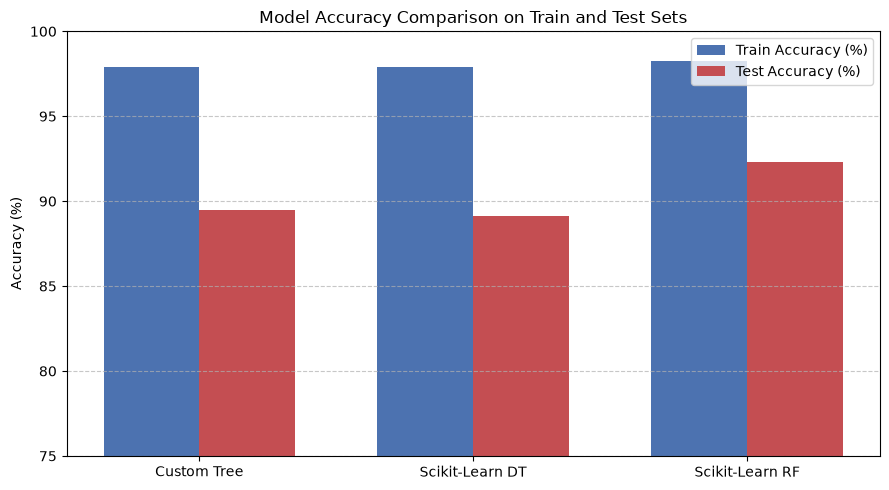

In [26]:
# --- Plot 1: Model Accuracy Comparison (Train vs Test) ---
models = ['Custom Tree', 'Scikit-Learn DT', 'Scikit-Learn RF']
train_acc = [c_train_acc * 100, sk_dt_train_acc * 100, sk_rf_train_acc * 100]
test_acc = [c_test_acc * 100, sk_dt_test_acc * 100, sk_rf_test_acc * 100]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))
plt.bar(x - width/2, train_acc, width, label='Train Accuracy (%)', color='#4C72B0')
plt.bar(x + width/2, test_acc, width, label='Test Accuracy (%)', color='#C44E52')

plt.ylabel('Accuracy (%)')
plt.title('Model Accuracy Comparison on Train and Test Sets')
plt.xticks(x, models)
plt.ylim(75, 100)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

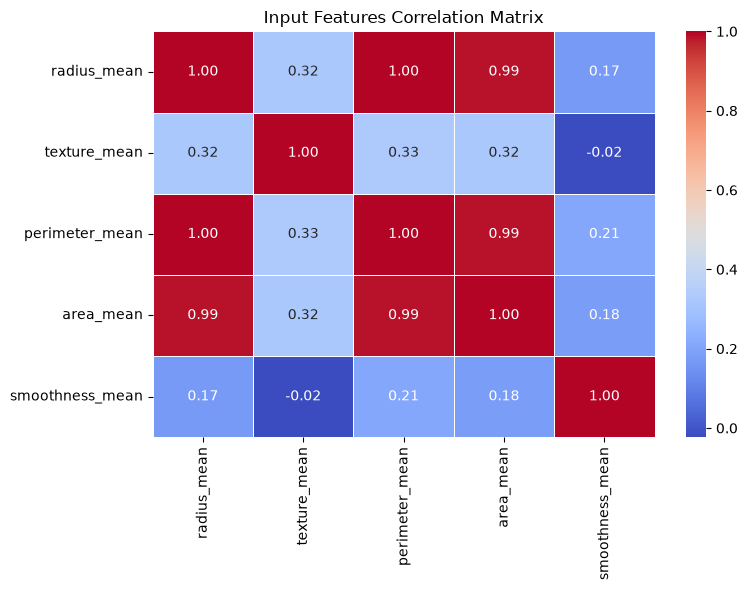

In [27]:
# --- Plot 2: Feature Correlation Heatmap ---
plt.figure(figsize=(8, 6))
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Input Features Correlation Matrix')
plt.tight_layout()
plt.show()